<p style="text-align: center;">University of Puerto Rico at Mayagüez<br>Department of Electrical and Computer Engineering</p>

<h1 style="text-align: center;">Understanding Adam: Adaptive Moment Estimation</h1>

<p style="text-align: center;">Homework: Exercises of D2L Section 12.10.5<br>
ICOM6015 - Neural Networks and Deep Learning, Fall 2026<br>
Diego Hernando Merchan Rueda - 502254366<br>
Instructor: J. Fernando Vega Riveros, PhD<br>
October 28, 2026</p>

**Summary.** This report answers the four exercises of Section 12.10.5 of *Dive into Deep Learning* [1, Sec. 12.10.5].
Adam and Yogi are implemented from scratch in NumPy and validated against the book.
Exercise 1 studies the learning rate experimentally, Exercise 2 derives an equivalent form of Adam that needs no bias correction,
Exercise 3 explains and tests why the learning rate must be reduced near convergence, and Exercise 4 reproduces a case in which Adam fails to converge while Yogi converges.

**Reproducibility.** All results come from the notebook `adam_exercises.ipynb` (submitted with this report), run with Python 3.14, NumPy 2.5.4, and Matplotlib 3.11.2 (`requirements.txt`).
All experiments use fixed seeds; the code is hidden in this PDF and available in the notebook.

## Part 0 — Setup: data, model, and optimizers (Adam, Yogi) from scratch
We reproduce the setup of D2L [1, Sec. 12.5]: linear regression on the NASA airfoil self-noise dataset [6]
(1500 samples, standardized features), minibatch size 10, 2 epochs, squared loss.
All experiments in later sections reuse these functions.


In [1]:
# --- Python standard library (built in, nothing to install) ---
import sys                  # info about the running Python; used to confirm we are in the .venv
import hashlib              # computes file hashes (SHA-1) to verify the dataset downloaded intact
import urllib.request       # downloads files from a URL (the airfoil dataset)
from pathlib import Path    # handles file/folder paths in an OS-independent way

# --- Third-party libraries (installed in the .venv with pip) ---
import numpy as np                  # numerical arrays and linear algebra: data, gradients, Adam/Yogi math
import matplotlib                   # plotting library (imported only to print its version)
import matplotlib.pyplot as plt     # matplotlib's plotting interface: loss curves and figures

In [2]:
# random seed
SEED = 0 
# point to the folder paths to save the data/figures
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
# create the folders if they don't exist; no error if they already do
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

### 0.1 Data
Airfoil self-noise dataset [6] (downloaded from D2L's data server [1, Sec. 12.5], integrity verified with SHA-1).
Each column is standardized to zero mean and unit variance; the last column is the target.

In [3]:
# dataset URL and expected hash (same as D2L)
URL = "http://d2l-data.s3-accelerate.amazonaws.com/airfoil_self_noise.dat"
SHA1 = "76e5be1548fd8222e5074cf0faae75edff8cf93f"
path = DATA_DIR / "airfoil_self_noise.dat"

# download once and verify the file is intact
if not path.exists():
    urllib.request.urlretrieve(URL, path)
assert hashlib.sha1(path.read_bytes()).hexdigest() == SHA1, "corrupted file"

# load and standardize each column (mean 0, std 1)
data = np.genfromtxt(path, delimiter="\t")
data = (data - data.mean(axis=0)) / data.std(axis=0)

# first 1500 rows: 5 input features (X) and the target noise level (y)
X, y = data[:1500, :-1], data[:1500, -1:]
print(X.shape, y.shape)

(1500, 5) (1500, 1)


### 0.2 Model, loss, and gradient
Linear model $\hat{y} = Xw + b$ with squared loss. The analytic gradient is checked against finite differences.

In [4]:
def predict(X, w, b):
    """Linear model prediction.
    Args:
        X: inputs, shape (B, d).
        w: weights, shape (d, 1).
        b: bias, shape (1, 1).
    Returns:
        Predictions y_hat = Xw + b, shape (B, 1).
    """
    return X @ w + b

def loss(X, y, w, b):
    """Squared loss averaged over samples: mean((y_hat - y)^2 / 2).
    Args:
        X: inputs, shape (B, d).
        y: targets, shape (B, 1).
        w, b: model parameters.
    Returns:
        Scalar loss.
    """
    return float(np.mean((predict(X, w, b) - y) ** 2) / 2)

def gradients(X, y, w, b):
    """Analytic gradient of the loss with respect to w and b.
    Args:
        X: inputs, shape (B, d).
        y: targets, shape (B, 1).
        w, b: model parameters.
    Returns:
        Dict {"w": dL/dw, "b": dL/db} with the same shapes as w and b.
    """
    r = predict(X, w, b) - y
    return {"w": X.T @ r / len(X), "b": r.mean(axis=0, keepdims=True)}

In [5]:
# random test point
rng = np.random.default_rng(SEED)
w, b = rng.normal(0, 1, (5, 1)), rng.normal(0, 1, (1, 1))
g = gradients(X, y, w, b)

# numerical gradient with central differences
h = 1e-6
num_w = np.zeros_like(w)
for i in range(len(w)):
    e = np.zeros_like(w); e[i] = h
    num_w[i] = (loss(X, y, w + e, b) - loss(X, y, w - e, b)) / (2 * h)
num_b = (loss(X, y, w, b + h) - loss(X, y, w, b - h)) / (2 * h)

# errors should be ~1e-10
print("max error w:", np.abs(num_w - g["w"]).max())
print("max error b:", abs(num_b - g["b"].item()))

max error w: 7.710050566739346e-11
max error b: 1.6279344539071872e-10


### 0.3 Optimizers
**Adam** [1, Sec. 12.10], [2]:
$$v_t = \beta_1 v_{t-1} + (1-\beta_1) g_t, \qquad s_t = \beta_2 s_{t-1} + (1-\beta_2) g_t^2$$
$$\hat{v}_t = \frac{v_t}{1-\beta_1^t}, \qquad \hat{s}_t = \frac{s_t}{1-\beta_2^t}, \qquad x_t = x_{t-1} - \frac{\eta\, \hat{v}_t}{\sqrt{\hat{s}_t} + \epsilon}$$

**Yogi** [1, Sec. 12.10], [4] only changes the second moment:
$$s_t = s_{t-1} + (1-\beta_2)\, g_t^2 \odot \operatorname{sgn}(g_t^2 - s_{t-1})$$

In [6]:
def init_states(params):
    """Create the optimizer state: first moment v and second moment s, both at 0.
    Args:
        params: dict of parameter arrays, e.g. {"w": ..., "b": ...}.
    Returns:
        Dict {name: {"v": zeros, "s": zeros}} with one entry per parameter.
    """
    return {k: {"v": np.zeros_like(p), "s": np.zeros_like(p)} for k, p in params.items()}

def adam(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """One Adam step. Updates params and states in place.
    Args:
        params: dict of parameter arrays.
        grads: dict of gradients, same keys as params.
        states: optimizer state from init_states.
        t: step number, starting at 1 (used for bias correction).
        lr: learning rate eta.
        beta1: decay rate of the first moment.
        beta2: decay rate of the second moment.
        eps: small constant to avoid division by zero.
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        # moving averages of the gradient and the squared gradient
        v[:] = beta1 * v + (1 - beta1) * g
        s[:] = beta2 * s + (1 - beta2) * g**2
        # bias correction
        v_hat = v / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)
        # parameter update
        params[k] -= lr * v_hat / (np.sqrt(s_hat) + eps)

def yogi(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-3):
    """One Yogi step. Same as adam() except for the second-moment update.
    Args:
        Same as adam(). D2L uses eps=1e-3 for Yogi.
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        v[:] = beta1 * v + (1 - beta1) * g
        # only difference from Adam: additive second-moment update
        s[:] = s + (1 - beta2) * g**2 * np.sign(g**2 - s)
        v_hat = v / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)
        params[k] -= lr * v_hat / (np.sqrt(s_hat) + eps)

### 0.4 Training loop
Fixed seed: same initialization and minibatch order in every run, so only the optimizer settings change.

In [7]:
def train(optimizer, hp, num_epochs=2, batch_size=10, seed=SEED):
    """Train linear regression with minibatches (equivalent to d2l.train_ch11).
    The same seed gives the same initialization and minibatch order,
    so runs differ only in the optimizer and its hyperparameters.
    Args:
        optimizer: update function, adam or yogi.
        hp: optimizer hyperparameters, e.g. {"lr": 0.01}.
        num_epochs: passes over the dataset.
        batch_size: samples per minibatch.
        seed: random seed.
    Returns:
        history: array of [epoch, full-dataset loss], recorded every 200 samples.
        params: final parameters {"w", "b"}.
    """
    rng = np.random.default_rng(seed)
    params = {"w": rng.normal(0, 0.01, (X.shape[1], 1)), "b": np.zeros((1, 1))}
    states = init_states(params)
    t, seen = 0, 0
    history = [(0.0, loss(X, y, params["w"], params["b"]))]

    for epoch in range(num_epochs):
        # shuffle the data every epoch
        idx = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            # one optimizer step on a minibatch
            batch = idx[start:start + batch_size]
            grads = gradients(X[batch], y[batch], params["w"], params["b"])
            t += 1
            optimizer(params, grads, states, t, **hp)
            # record the full-dataset loss every 200 samples
            seen += len(batch)
            if seen % 200 == 0:
                history.append((seen / len(X), loss(X, y, params["w"], params["b"])))
    return np.array(history), params

### 0.5 Sanity check
D2L [1, Sec. 12.10] reports a final loss of about 0.24 for both optimizers with $\eta = 0.01$.

Adam final loss: 0.2436
Yogi final loss: 0.2433


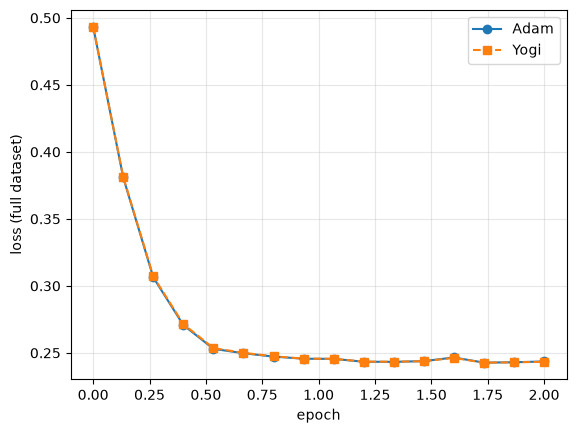

In [8]:
# same conditions for both optimizers (D2L reports ~0.24)
hist_adam, _ = train(adam, {"lr": 0.01})
hist_yogi, _ = train(yogi, {"lr": 0.01})
print(f"Adam final loss: {hist_adam[-1, 1]:.4f}")
print(f"Yogi final loss: {hist_yogi[-1, 1]:.4f}")

# loss curves
plt.plot(*hist_adam.T, "o-", label="Adam")
plt.plot(*hist_yogi.T, "s--", label="Yogi")
plt.xlabel("epoch"); plt.ylabel("loss (full dataset)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Exercise 1 - Learning rate
*Adjust the learning rate and observe and analyze the experimental results.* [1, Sec. 12.10.5]

**Setup:** Adam on the Part 0 problem. Only the learning rate changes: $\eta \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$.
Everything else is fixed ($\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-6}$, batch size 10, 2 epochs = 300 steps).
Each learning rate is run with 5 seeds (different initialization and minibatch order).
The optimal loss, computed exactly with least squares, is used as a reference.

**Expectation (before running):** Since Adam moves each parameter by roughly $\eta$ per step,
the smallest learning rate should change the weights the least and take the longest to approach
the minimum loss: with $\eta = 10^{-4}$, each weight can move at most $300 \times 10^{-4} = 0.03$ in total.
A large learning rate ($\eta = 1$) should make steps big enough to overshoot the minimum,
so the loss may jump around instead of settling.

In [9]:
# optimal loss: exact least-squares solution (the best any optimizer can reach)
A = np.hstack([X, np.ones((len(X), 1))])
sol = np.linalg.lstsq(A, y, rcond=None)[0]
OPT_LOSS = loss(X, y, sol[:-1], sol[-1:])
print(f"Optimal loss: {OPT_LOSS:.4f}")

Optimal loss: 0.2417


In [10]:
# learning rates to compare and seeds for repetition
LRS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
SEEDS = range(5)

# run every (learning rate, seed) pair
results = {lr: [train(adam, {"lr": lr}, seed=s)[0] for s in SEEDS] for lr in LRS}

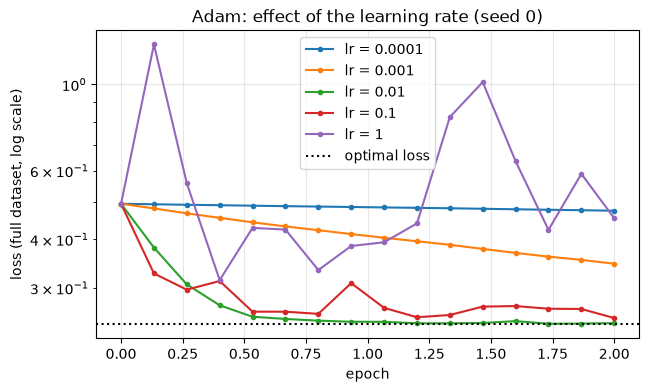

In [11]:
# loss curves for seed 0, with the optimal loss as reference
fig, ax = plt.subplots(figsize=(7, 4))
for lr in LRS:
    ax.plot(*results[lr][0].T, "o-", ms=3, label=f"lr = {lr:g}")
ax.axhline(OPT_LOSS, color="k", ls=":", label="optimal loss")
ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (full dataset, log scale)")
ax.set_title("Adam: effect of the learning rate (seed 0)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex1_learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# summary over seeds: final loss (mean ± std), best loss reached, and gap to the optimum
print(f"{'lr':>8} | {'final loss':>16} | {'best loss':>9} | {'final - optimal':>15}")
for lr in LRS:
    final = np.array([h[-1, 1] for h in results[lr]])
    best = np.array([h[:, 1].min() for h in results[lr]])
    print(f"{lr:>8g} | {final.mean():.4f} ± {final.std():.4f} | {best.mean():>9.4f} | {final.mean() - OPT_LOSS:>15.4f}")

      lr |       final loss | best loss | final - optimal
  0.0001 | 0.4753 ± 0.0036 |    0.4753 |          0.2336
   0.001 | 0.3415 ± 0.0024 |    0.3415 |          0.0998
    0.01 | 0.2436 ± 0.0010 |    0.2427 |          0.0019
     0.1 | 0.2707 ± 0.0171 |    0.2501 |          0.0290
       1 | 0.8903 ± 0.6456 |    0.3112 |          0.6486


### Results
| $\eta$ | Final loss (mean ± std, 5 seeds) | Best loss | Final − optimal |
|---|---|---|---|
| $10^{-4}$ | 0.4753 ± 0.0036 | 0.4753 | 0.2336 |
| $10^{-3}$ | 0.3415 ± 0.0024 | 0.3415 | 0.0998 |
| $10^{-2}$ | 0.2436 ± 0.0010 | 0.2427 | 0.0019 |
| $10^{-1}$ | 0.2707 ± 0.0171 | 0.2501 | 0.0290 |
| $1$ | 0.8903 ± 0.6456 | 0.3112 | 0.6486 |

Optimal loss (least squares): 0.2417.

### Observations
- $\eta = 10^{-4}$ and $10^{-3}$: the loss decreases monotonically (best = final) but stays far from the optimum after 2 epochs.
- $\eta = 10^{-2}$: fastest stable decrease; the final loss is within 0.002 of the optimum, with very low variance across seeds.
- $\eta = 10^{-1}$: the loss drops quickly at first but then fluctuates; the final loss is worse than the best loss reached.
- $\eta = 1$: the loss oscillates strongly, the final value is far above the best one, and the result varies widely between seeds. It does not diverge to infinity.

### Interpretation
- Adam's update is approximately $\eta \cdot \hat{v}_t / \sqrt{\hat{s}_t}$, where $\hat{v}_t / \sqrt{\hat{s}_t}$ has magnitude of order 1, so each parameter moves by roughly $\eta$ per step regardless of the gradient scale.
- Small $\eta$: in 300 steps a weight can move at most about $300\eta$ (0.03 for $\eta = 10^{-4}$), which is not enough to reach the minimum. These runs have not converged yet; they are slow, not unstable.
- Large $\eta$: steps are larger than the distance to the minimum, so the optimizer overshoots and keeps jumping around it. The best loss is reached and then lost. Because each step is bounded by about $\eta$, the loss stays bounded instead of diverging.
- Even the best $\eta$ does not reach the exact optimum: with noisy minibatch gradients and a constant $\eta$, Adam keeps taking steps of size about $\eta$ near the minimum and fluctuates around it (see Exercise 3).

### Conclusion
The expectation was confirmed: the learning rate sets the step size, creating a trade-off between speed (too small is slow) and stability (too large overshoots and oscillates). For this problem, $\eta = 10^{-2}$ gives the best balance. In neural network training the best $\eta$ depends on the problem, so it must be tuned, typically by trying values on a logarithmic scale as done here and as recommended in the course notes [7, p. 20].

## Exercise 2 — Removing the bias correction
*Can you rewrite the momentum and second-moment updates such that they do not require a bias correction?* [1, Sec. 12.10.5]

### Why the bias appears
The memory starts at $v_0 = 0$. Unrolling the recursion $v_t = \beta v_{t-1} + (1-\beta) g_t$ shows that $v_t$ is a weighted sum of the gradients:
$$v_t = (1-\beta)\left(\beta^{t-1} g_1 + \beta^{t-2} g_2 + \cdots + g_t\right).$$
The weights add up to (geometric series)
$$(1-\beta)\left(1 + \beta + \cdots + \beta^{t-1}\right) = (1-\beta)\,\frac{1-\beta^t}{1-\beta} = 1-\beta^t$$
instead of 1: the missing weight $\beta^t$ belongs to the zero initial value. Therefore $v_t$ is smaller than it should be, especially in early steps
(e.g. with $\beta = 0.9$ and $g_1 = 5$: $v_1 = 0.5$, ten times too small). This error is the **bias**, and Adam removes it [2, Sec. 3] by dividing by $1-\beta^t$:
$\hat v_t = v_t / (1-\beta^t)$.

### Derivation
Starting point (D2L [1, Sec. 12.10]): **(A)** $v_t = \beta v_{t-1} + (1-\beta) g_t$ and **(B)** $\hat v_t = v_t/(1-\beta^t)$.
Goal: a recursion that gives $\hat v_t$ directly from $\hat v_{t-1}$ and $g_t$, without computing $v_t$ or correcting afterwards.

1. **Solve (B) for $v_t$** by multiplying both sides by $1-\beta^t$, which undoes the division:
$$v_t = (1-\beta^t)\,\hat v_t$$
2. **The same relation holds at every step**, so replacing $t$ by $t-1$:
$$v_{t-1} = (1-\beta^{t-1})\,\hat v_{t-1}$$
3. **Substitute** both expressions into (A). Each $v$ is replaced by an equal quantity, so the equality still holds, and only corrected values remain:
$$(1-\beta^t)\,\hat v_t = \beta\,(1-\beta^{t-1})\,\hat v_{t-1} + (1-\beta)\,g_t$$
4. **Simplify** with the distributive property and the product of powers ($\beta \cdot \beta^{t-1} = \beta^{t}$):
$$\beta\,(1-\beta^{t-1}) = \beta - \beta^t \quad\Rightarrow\quad (1-\beta^t)\,\hat v_t = (\beta-\beta^t)\,\hat v_{t-1} + (1-\beta)\,g_t$$
5. **Divide both sides by $1-\beta^t$** (each term separately). This is allowed because $0 \le \beta < 1$ implies $\beta^t < 1$, so $1-\beta^t \neq 0$:
$$\hat v_t = \frac{\beta-\beta^t}{1-\beta^t}\,\hat v_{t-1} + \frac{1-\beta}{1-\beta^t}\,g_t$$
6. **The two coefficients add up to 1.** They share the denominator, so the numerators are added; $+\beta$ and $-\beta$ cancel:
$$\frac{\beta-\beta^t}{1-\beta^t} + \frac{1-\beta}{1-\beta^t} = \frac{1-\beta^t}{1-\beta^t} = 1$$
This means $\hat v_t$ is a proper weighted average of the previous memory and the new gradient, which the uncorrected $v_t$ is not.
7. **Name the coefficient of $g_t$** as $\alpha_t$. Since both coefficients add up to 1, the other one is $1-\alpha_t$. The same steps applied to $s_t$ (with $\beta_2$ and $g_t^2$) give the second result:
$$\boxed{\hat v_t = (1-\alpha_t)\,\hat v_{t-1} + \alpha_t\, g_t, \qquad \alpha_t = \frac{1-\beta_1}{1-\beta_1^{t}}}$$
$$\boxed{\hat s_t = (1-\gamma_t)\,\hat s_{t-1} + \gamma_t\, g_t^2, \qquad \gamma_t = \frac{1-\beta_2}{1-\beta_2^{t}}}$$
The parameter update uses these values directly: $x_t = x_{t-1} - \eta\,\hat v_t/(\sqrt{\hat s_t} + \epsilon)$, with no correction step.

### Why the rewritten version has no bias
- **First step:** $\alpha_1 = \frac{1-\beta}{1-\beta} = 1$, so $\hat v_1 = 0 \cdot \hat v_0 + 1 \cdot g_1 = g_1$. The initial value is multiplied by 0 and has no influence.
  In the original recursion, the bias came from the zero initial value keeping part of the weight ($\beta$ in the first step); here it keeps none.
- **Every later step:** the coefficients always add up to 1 (step 6), so each $\hat v_t$ is a proper average. There is no bias at any step, so no correction is needed.
- **Behavior over time:** early on, $1-\beta^t \approx t(1-\beta)$, so $\alpha_t \approx 1/t$ and the update is a plain average of all gradients seen so far (with few gradients, all count equally).
  As $t$ grows, $\beta^t \to 0$ and $\alpha_t \to 1-\beta$: the update becomes Adam's usual exponential moving average, which gradually forgets old gradients.

| $t$ | 1 | 2 | 3 | 4 | $\to\infty$ |
|---|---|---|---|---|---|
| $\alpha_t$ ($\beta_1 = 0.9$) | 1 | 0.526 | 0.369 | 0.291 | 0.1 |
| $\gamma_t$ ($\beta_2 = 0.999$) | 1 | 0.500 | 0.334 | 0.250 | 0.001 |

**Numerical check** (example with $\beta = 0.9$, $g_1 = 5$, $g_2 = 3$): Adam gives $v_2 = 0.75$ and $\hat v_2 = 0.75/0.19 = 3.947$.
The rewritten formula gives $\hat v_2 = 0.4737 \cdot 5 + 0.5263 \cdot 3 = 3.947$ without computing $v_2$.

In [13]:
def adam_no_bc(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """Adam rewritten without a bias-correction step (Exercise 2).
    Uses time-varying weights alpha_t = (1 - beta) / (1 - beta^t), so the
    stored v and s are already the corrected estimates v_hat and s_hat.
    Args:
        Same as adam().
    """
    a1 = (1 - beta1) / (1 - beta1**t)
    a2 = (1 - beta2) / (1 - beta2**t)
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        # moving averages with time-varying weights
        v[:] = (1 - a1) * v + a1 * g
        s[:] = (1 - a2) * s + a2 * g**2
        # parameter update, no correction step
        params[k] -= lr * v / (np.sqrt(s) + eps)

def adam_raw(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """Adam with the bias correction simply removed (for comparison only).
    Args:
        Same as adam().
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        v[:] = beta1 * v + (1 - beta1) * g
        s[:] = beta2 * s + (1 - beta2) * g**2
        params[k] -= lr * v / (np.sqrt(s) + eps)

In [14]:
# verification: the rewritten version must give the same trajectory as Adam
hist_a, params_a = train(adam, {"lr": 0.01})
hist_b, params_b = train(adam_no_bc, {"lr": 0.01})
print("max weight difference:", np.abs(params_a["w"] - params_b["w"]).max())
print("max loss difference:  ", np.abs(hist_a - hist_b).max())

max weight difference: 5.551115123125783e-17
max loss difference:   1.6653345369377348e-16


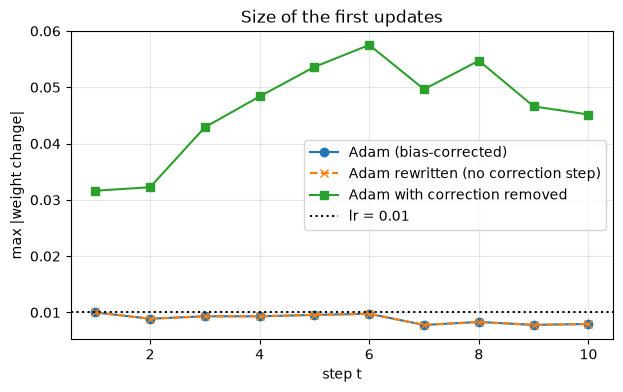

In [15]:
def first_step_sizes(optimizer, lr=0.01, n_steps=10, seed=SEED):
    """Largest weight change in each of the first optimizer steps.
    Args:
        optimizer: update function (adam, adam_no_bc, adam_raw).
        lr: learning rate.
        n_steps: number of steps to measure.
        seed: random seed (same init and minibatch order as train()).
    Returns:
        Array with max |w_t - w_{t-1}| for t = 1..n_steps.
    """
    rng = np.random.default_rng(seed)
    params = {"w": rng.normal(0, 0.01, (X.shape[1], 1)), "b": np.zeros((1, 1))}
    states = init_states(params)
    idx = rng.permutation(len(X))
    sizes = []
    for t in range(1, n_steps + 1):
        batch = idx[(t - 1) * 10: t * 10]
        w_old = params["w"].copy()
        optimizer(params, gradients(X[batch], y[batch], params["w"], params["b"]), states, t, lr=lr)
        sizes.append(np.abs(params["w"] - w_old).max())
    return np.array(sizes)

# step sizes with and without bias correction (lr = 0.01)
steps = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, first_step_sizes(adam), "o-", label="Adam (bias-corrected)")
ax.plot(steps, first_step_sizes(adam_no_bc), "x--", label="Adam rewritten (no correction step)")
ax.plot(steps, first_step_sizes(adam_raw), "s-", label="Adam with correction removed")
ax.axhline(0.01, color="k", ls=":", label="lr = 0.01")
ax.set_xlabel("step t"); ax.set_ylabel("max |weight change|")
ax.set_title("Size of the first updates")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex2_first_steps.png", dpi=150, bbox_inches="tight")
plt.show()

### Numerical verification
- **Observation:** the rewritten optimizer produces the same weights and losses as Adam, up to floating-point rounding (~$10^{-16}$).
  The rewrite is therefore exactly equivalent, not an approximation.
- **Observation:** with the correction simply removed, the first updates are about 3–5 times larger than $\eta$ (0.0316 at $t=1$, i.e. $\sqrt{1000}/10 \cdot \eta$),
  while both correct versions move each weight by about $\eta$.
- **Interpretation:** without correction, $v_1 = 0.1\,g_1$ is shrunk by a factor of 10 but $\sqrt{s_1} = \sqrt{0.001}\,|g_1|$ is shrunk by a factor of about 31.6,
  so their ratio is too large by $31.6/10 \approx 3.16$. At the start of training, when the parameters are farthest from a good solution,
  this would produce unexpectedly large steps, as Kingma and Ba also note [2, Sec. 3]. Bias correction, or the equivalent rewrite, keeps the step size consistent with $\eta$ from the first iteration,
  which matters for deep networks, where early instability can push the weights into poor regions.

## Exercise 3 — Reducing the learning rate
*Why do you need to reduce the learning rate $\eta$ as we converge?* [1, Sec. 12.10.5]

### Reasoning
1. **Adam's step has a size of about $\eta$.** The update is $\Delta x_t = \eta\,\hat v_t / (\sqrt{\hat s_t} + \epsilon)$.
   Since $\sqrt{\hat s_t}$ is the root mean square of recent gradients and $\hat v_t$ is their average, the ratio $\hat v_t/\sqrt{\hat s_t}$ is typically of order 1 or smaller,
   so each parameter moves by about $\eta$ or less per step, regardless of the gradient scale (Part 0, Exercise 1).
2. **Near the minimum the minibatch gradient does not vanish.** It can be written as $g_t = \nabla L(x_t) + \xi_t$, where $\nabla L(x_t) \to 0$ at the minimum
   but the noise $\xi_t$ (from using 10 samples instead of all 1500) does not. Then $\sqrt{\hat s_t}$ tracks the noise level and $\hat v_t$ is an average of about 10 noisy values,
   so the ratio stays of order 1 and the step stays proportional to $\eta$. The parameters keep moving randomly inside a region around the minimum whose size grows with $\eta$.
   In full-batch gradient descent the step $\eta\,\nabla L$ shrinks by itself near the minimum; Adam's normalization and minibatch noise remove that effect.
3. **Consequence.** With a constant $\eta$, the loss stops at a level above the optimum that depends on $\eta$ (Exercise 1: 0.2436 vs. 0.2417 for $\eta = 10^{-2}$).
   Converging to the minimum requires $\eta_t \to 0$, but not too fast. The classical stochastic-approximation conditions [5] are
   $$\sum_{t=1}^{\infty} \eta_t = \infty \quad \text{(enough total movement to reach the minimum)}, \qquad \sum_{t=1}^{\infty} \eta_t^2 < \infty \quad \text{(the accumulated noise stays bounded)}.$$
   Kingma and Ba's convergence analysis of Adam [2, Sec. 4] uses $\eta_t = \eta/\sqrt{t}$.

**Setup:** Adam on the Part 0 problem for 10 epochs (1500 steps), 5 seeds, comparing a constant $\eta$ with two decaying schedules:
step decay ($\eta_t = \eta \cdot 0.1^{\lfloor t/450 \rfloor}$, i.e. $\times 0.1$ every 3 epochs) and $\eta_t = \eta/\sqrt{t}$.

**Expectation:** with a constant $\eta$, the loss should plateau above the optimum, higher for larger $\eta$. With a decaying $\eta$, it should keep getting closer.
If $\eta$ starts small and decays quickly, progress should stall before reaching the minimum.

In [16]:
def with_schedule(optimizer, schedule):
    """Wrap an optimizer so the learning rate changes with the step number.
    Args:
        optimizer: update function (adam, yogi, ...).
        schedule: function (t, lr) -> learning rate used at step t.
    Returns:
        Optimizer function with the same signature as adam().
    """
    def step(params, grads, states, t, lr, **kwargs):
        optimizer(params, grads, states, t, schedule(t, lr), **kwargs)
    return step

# learning-rate schedules: eta_t as a function of the step t and the initial eta
constant = lambda t, lr: lr
step_decay = lambda t, lr: lr * 0.1 ** (t // 450)    # x0.1 every 3 epochs (150 steps per epoch)
inv_sqrt = lambda t, lr: lr / np.sqrt(t)             # eta / sqrt(t), as in Kingma & Ba's analysis

# configurations to compare: (label, schedule, initial learning rate)
CONFIGS = [
    ("constant, lr = 0.1", constant, 0.1),
    ("constant, lr = 0.01", constant, 0.01),
    ("step decay, lr = 0.1", step_decay, 0.1),
    ("1/sqrt(t), lr = 0.1", inv_sqrt, 0.1),
    ("1/sqrt(t), lr = 0.01", inv_sqrt, 0.01),
]
EPOCHS3 = 10

# run every configuration with the same 5 seeds
results3 = {name: [train(with_schedule(adam, sched), {"lr": lr}, num_epochs=EPOCHS3, seed=s) for s in SEEDS]
            for name, sched, lr in CONFIGS}

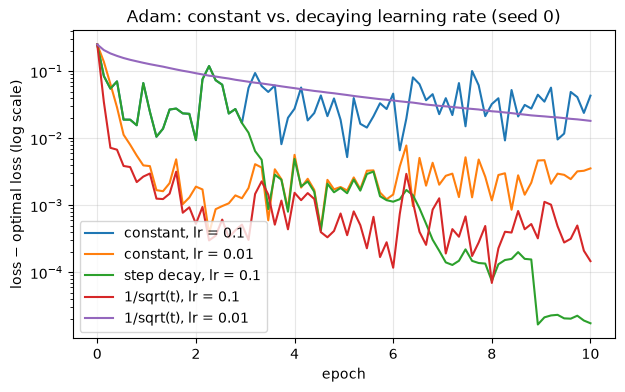

         configuration |   final − optimal | fluctuation | distance to optimum
    constant, lr = 0.1 | 0.04374 ± 0.00314 |     0.01420 |              0.2864
   constant, lr = 0.01 | 0.00251 ± 0.00090 |     0.00122 |              0.0736
  step decay, lr = 0.1 | 0.00007 ± 0.00006 |     0.00000 |              0.0128
   1/sqrt(t), lr = 0.1 | 0.00023 ± 0.00013 |     0.00021 |              0.0185
  1/sqrt(t), lr = 0.01 | 0.01655 ± 0.00101 |     0.00086 |              0.2761


In [17]:
# loss above the optimum for seed 0 (log scale)
fig, ax = plt.subplots(figsize=(7, 4))
for name, _, _ in CONFIGS:
    hist = results3[name][0][0]
    ax.plot(hist[:, 0], hist[:, 1] - OPT_LOSS, label=name)
ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("loss − optimal loss (log scale)")
ax.set_title("Adam: constant vs. decaying learning rate (seed 0)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex3_lr_decay.png", dpi=150, bbox_inches="tight")
plt.show()

# summary over seeds: gap to the optimum, fluctuation in the last epoch, distance to the optimal weights
w_opt, b_opt = sol[:-1], sol[-1:]
print(f"{'configuration':>22} | {'final − optimal':>17} | {'fluctuation':>11} | {'distance to optimum':>19}")
for name, _, _ in CONFIGS:
    gap = np.array([h[-1, 1] - OPT_LOSS for h, _ in results3[name]])
    fluct = np.array([h[h[:, 0] >= EPOCHS3 - 1, 1].std() for h, _ in results3[name]])
    dist = np.array([np.sqrt(np.sum((p["w"] - w_opt) ** 2) + np.sum((p["b"] - b_opt) ** 2)) for _, p in results3[name]])
    print(f"{name:>22} | {gap.mean():.5f} ± {gap.std():.5f} | {fluct.mean():>11.5f} | {dist.mean():>19.4f}")

### Results (10 epochs, mean ± std over 5 seeds)
| Schedule | Final loss − optimal | Fluctuation (std, last epoch) | Distance to optimal weights |
|---|---|---|---|
| constant, $\eta = 0.1$ | 0.04374 ± 0.00314 | 0.01420 | 0.2864 |
| constant, $\eta = 0.01$ | 0.00251 ± 0.00090 | 0.00122 | 0.0736 |
| step decay, $\eta = 0.1$ | 0.00007 ± 0.00006 | 0.00000 | 0.0128 |
| $1/\sqrt{t}$, $\eta = 0.1$ | 0.00023 ± 0.00013 | 0.00021 | 0.0185 |
| $1/\sqrt{t}$, $\eta = 0.01$ | 0.01655 ± 0.00101 | 0.00086 | 0.2761 |

### Observations
- With a constant $\eta$, the loss reaches a plateau and keeps fluctuating. Training 10 epochs instead of 2 does not help: the gap for $\eta = 0.01$ is 0.0025 (0.0019 after 2 epochs).
- The plateau is higher for larger $\eta$: the gap with $\eta = 0.1$ is about 17 times larger than with $\eta = 0.01$.
- Step decay from $\eta = 0.1$ ends about 36 times closer to the optimum than the best constant rate, with almost no fluctuation. Each drop of $\eta$ produces a visible drop in the loss.
- $1/\sqrt{t}$ from $\eta = 0.1$ also gets close to the optimum. From $\eta = 0.01$, it decreases steadily but slowly and ends worse than the constant $\eta = 0.01$.

### Interpretation
- The results support the reasoning: with a constant $\eta$, minibatch noise keeps the step at about $\eta$, so the parameters stay in a region around the minimum whose size grows with $\eta$. More training does not shrink that region.
- Reducing $\eta$ shrinks the region, so the parameters settle closer to the minimum. This is why a decaying schedule reaches a much lower loss.
- Decaying too early or too fast also fails: $1/\sqrt{t}$ starting at $0.01$ reduces the step before the parameters reach the minimum. A large $\eta$ is useful early (fast progress) and a small one late (precision).

### Qualifications and limitations
- The convergence conditions above come from convex analysis. This linear regression is convex, but deep networks are not, so they are a guide rather than a guarantee.
- In neural network training the goal is good generalization, not the exact minimum of the training loss. Some gradient noise can help escape saddle points and sharp minima, so schedules (step, cosine, warmup + decay) are chosen empirically.
- A decaying $\eta$ is necessary but not sufficient for Adam. Reddi et al. [3] showed that Adam can fail to converge even with a decaying $\eta$, because the effective step $\eta/\sqrt{\hat s_t}$ can grow when $\hat s_t$ decreases. This motivates variants such as AMSGrad and Yogi (Exercise 4).
- A schedule adds hyperparameters (initial $\eta$, decay factor, and timing) that also need tuning.

### Conclusion
Near the minimum, Adam keeps fluctuating because minibatch gradients are noisy and do not vanish, and Adam takes steps of up to about $\eta$ with them.
With a constant $\eta$ it never settles at the minimum, and training longer does not help.
The learning rate must be reduced so that the fluctuations shrink, but not too fast: if the steps become very small before the parameters reach the minimum, training stalls far from it and the loss stays high
(as with $1/\sqrt{t}$ starting at $\eta = 0.01$).
The practical limitation is that choosing how to reduce $\eta$ is not straightforward, neither too fast nor too slow.
In a real network, such as my gesture-recognition project, the schedule should be adjusted while monitoring validation performance, because the goal is to recognize the same gestures in images the network has never seen, not to reach the exact minimum of the training loss.

## Exercise 4 — Adam versus Yogi
*Try to construct a case for which Adam diverges and Yogi converges.* [1, Sec. 12.10.5]

### Setup: Reddi et al.'s counterexample [3, Sec. 3]
A single parameter $x \in [-1, 1]$ is optimized online. At step $t$ the loss is
$$f_t(x) = \begin{cases} C\,x & \text{if } t \bmod 3 = 1 \\ -x & \text{otherwise} \end{cases} \qquad\Longrightarrow\qquad g_t = +C,\ -1,\ -1,\ +C,\ -1,\ -1,\ \dots$$
Over one cycle the total gradient is $C - 2 > 0$ (for $C > 2$), so the average loss decreases as $x$ decreases and the optimum is $x^* = -1$.
The large gradient is rare (1 of every 3 steps) but carries the correct information.
After each update, $x$ is projected back onto $[-1, 1]$. Both optimizers use the Part 0 implementations, $\eta_t = 0.5/\sqrt{t}$, $x_0 = 0$, 20000 steps,
and $\beta_1 = 0$ (no momentum) so that the effect of the second moment is isolated. Main case: $C = 3$, $\beta_2 = 0.1$, as in Reddi et al. [3, Sec. 3] ($\beta_2 = 1/(1+C^2)$).

**Expectation:** Adam divides each gradient by $\sqrt{\hat s_t}$. With a short memory ($\beta_2 = 0.1$), $\hat s_t$ quickly forgets the large gradient, so the small gradients get amplified
and the rare large one loses its weight. Yogi changes $s_t$ by at most $(1-\beta_2)\,g_t^2$ per step, so it remembers the large gradient and keeps the small ones small.

In [18]:
def cyclic(C):
    """Gradient sequence of Reddi et al.'s counterexample: f_t(x) = C x every third step, -x otherwise.
    Args:
        C: size of the rare large gradient (C > 2, so the optimum on [-1, 1] is x = -1).
    Returns:
        Function (t, rng) -> gradient at step t.
    """
    return lambda t, rng: C if t % 3 == 1 else -1.0

def stochastic(C, p):
    """Stochastic version: gradient C with probability p, -1 otherwise.
    Args:
        C: size of the rare large gradient.
        p: probability of the large gradient (C p - (1 - p) > 0, so the optimum is x = -1).
    Returns:
        Function (t, rng) -> gradient at step t.
    """
    return lambda t, rng: C if rng.random() < p else -1.0

def run_online(optimizer, grad_fn, T=20000, lr=0.5, seed=0, **hp):
    """Optimize a scalar x in [-1, 1] with the given gradient sequence (projected updates).
    Uses the same adam()/yogi() functions as Part 0, with eta_t = lr / sqrt(t).
    Args:
        optimizer: adam or yogi.
        grad_fn: function (t, rng) -> gradient.
        T: number of steps.
        lr: initial learning rate.
        seed: random seed (only used by stochastic gradients).
        **hp: extra optimizer hyperparameters (beta1, beta2, eps).
    Returns:
        Array with x after every step.
    """
    rng = np.random.default_rng(seed)
    step = with_schedule(optimizer, inv_sqrt)
    params = {"x": np.zeros((1, 1))}
    states = init_states(params)
    xs = np.empty(T)
    for t in range(1, T + 1):
        step(params, {"x": np.full((1, 1), grad_fn(t, rng))}, states, t, lr, **hp)
        # projection: keep x inside the feasible set [-1, 1]
        np.clip(params["x"], -1, 1, out=params["x"])
        xs[t - 1] = params["x"].item()
    return xs

Adam final x: +0.999 | Yogi final x: -0.998 | optimum: -1


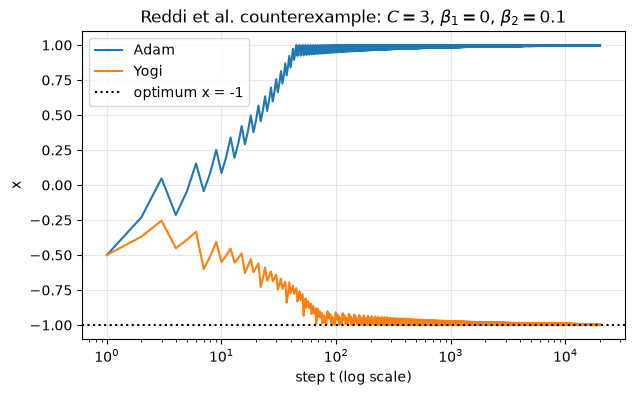

In [19]:
# main case: C = 3, beta1 = 0, beta2 = 0.1 (Reddi et al.'s setting, beta2 = 1 / (1 + C^2))
hp4 = {"beta1": 0.0, "beta2": 0.1}
xs_adam = run_online(adam, cyclic(3), **hp4)
xs_yogi = run_online(yogi, cyclic(3), **hp4)
print(f"Adam final x: {xs_adam[-1]:+.3f} | Yogi final x: {xs_yogi[-1]:+.3f} | optimum: -1")

fig, ax = plt.subplots(figsize=(7, 4))
steps4 = np.arange(1, len(xs_adam) + 1)
ax.plot(steps4, xs_adam, label="Adam")
ax.plot(steps4, xs_yogi, label="Yogi")
ax.axhline(-1, color="k", ls=":", label="optimum x = -1")
ax.set_xscale("log")
ax.set_xlabel("step t (log scale)"); ax.set_ylabel("x")
ax.set_title(r"Reddi et al. counterexample: $C = 3$, $\beta_1 = 0$, $\beta_2 = 0.1$")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex4_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# systematic sweep: final x (mean of the last 1000 steps) for several C and beta2
B2_VALUES = [0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 0.999]
print(f"{'':>12} | " + " | ".join(f"b2={b2:<5}" for b2 in B2_VALUES))
for C in [3, 5, 10]:
    for name, opt in [("adam", adam), ("yogi", yogi)]:
        row = [run_online(opt, cyclic(C), beta1=0.0, beta2=b2)[-1000:].mean() for b2 in B2_VALUES]
        print(f"C={C:<2} {name:>6} | " + " | ".join(f"{x:+8.2f}" for x in row))

             | b2=0.1   | b2=0.3   | b2=0.5   | b2=0.7   | b2=0.9   | b2=0.99  | b2=0.999


C=3    adam |    +1.00 |    +1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


C=3    yogi |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


C=5    adam |    +1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


C=5    yogi |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


C=10   adam |    -0.72 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


C=10   yogi |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00 |    -1.00


In [21]:
def normalized_steps(optimizer, C=3, beta2=0.1, T=3000, eps=None):
    """Normalized gradient g_t / sqrt(s_hat_t) for the last cycle of the cyclic sequence (beta1 = 0).
    Args:
        optimizer: adam or yogi.
        C: size of the large gradient.
        beta2: second-moment decay rate.
        T: steps to run before reading the last cycle.
        eps: epsilon (defaults to the optimizer's own default).
    Returns:
        List of (g_t, sqrt(s_hat_t), g_t / sqrt(s_hat_t)) for the last 6 steps.
    """
    params = {"x": np.zeros((1, 1))}
    states = init_states(params)
    out = []
    kw = {} if eps is None else {"eps": eps}
    for t in range(1, T + 1):
        g = C if t % 3 == 1 else -1.0
        optimizer(params, {"x": np.full((1, 1), g)}, states, t, lr=0.0, beta1=0.0, beta2=beta2, **kw)
        s_hat = states["x"]["s"].item() / (1 - beta2**t)
        out.append((g, np.sqrt(s_hat), g / np.sqrt(s_hat)))
    return out[-6:]

# the update is x <- x - eta * (normalized gradient), so a positive sum per cycle pushes x toward -1 (correct)
for name, opt in [("Adam", adam), ("Yogi", yogi)]:
    rows = normalized_steps(opt)
    print(f"{name}: " + "  ".join(f"g={g:+.0f}, sqrt(s)={r:.2f}, g/sqrt(s)={n:+.2f}" for g, r, n in rows[:3]))
    print(f"      sum over 6 steps (2 cycles) of g/sqrt(s): {sum(n for _, _, n in rows):+.2f} | true gradient sum: {sum(g for g, _, _ in rows):+.0f}")

Adam: g=+3, sqrt(s)=2.86, g/sqrt(s)=+1.05  g=-1, sqrt(s)=1.31, g/sqrt(s)=-0.76  g=-1, sqrt(s)=1.04, g/sqrt(s)=-0.97
      sum over 6 steps (2 cycles) of g/sqrt(s): -1.36 | true gradient sum: +2
Yogi: g=+3, sqrt(s)=3.15, g/sqrt(s)=+0.95  g=-1, sqrt(s)=3.00, g/sqrt(s)=-0.33  g=-1, sqrt(s)=2.85, g/sqrt(s)=-0.35
      sum over 6 steps (2 cycles) of g/sqrt(s): +0.49 | true gradient sum: +2


In [22]:
# stochastic version with Adam's default beta1 = 0.9: C = 50, p = 0.025 (expected gradient +0.275, optimum x = -1)
print(f"{'beta2':>6} | {'Adam: mean x (last 1000), 5 seeds':>40} | {'Yogi: mean x (last 1000), 5 seeds':>40}")
for b2 in [0.99, 0.999]:
    res = {name: [run_online(opt, stochastic(50, 0.025), seed=s, beta1=0.9, beta2=b2)[-1000:].mean() for s in SEEDS]
           for name, opt in [("adam", adam), ("yogi", yogi)]}
    print(f"{b2:>6} | " + " | ".join(f"{np.mean(v):+.2f} {np.round(v, 2)}".rjust(40) for v in res.values()))

 beta2 |        Adam: mean x (last 1000), 5 seeds |        Yogi: mean x (last 1000), 5 seeds


  0.99 |    -0.36 [-0.77  0.22  0.08 -0.95 -0.37] |    -0.45 [-0.86 -0.26 -0.49 -0.4  -0.24]


 0.999 |    -0.92 [-0.94 -0.98 -0.87 -0.98 -0.81] |    -0.98 [-0.99 -1.   -0.97 -1.   -0.96]


### Results
**Main case** ($C = 3$, $\beta_1 = 0$, $\beta_2 = 0.1$): Adam ends at $x = +1.00$, the worst point of the feasible set, while Yogi ends at $x = -1.00$, the optimum.

**Normalized gradient $g_t/\sqrt{\hat s_t}$ over one cycle** (steady state):

| Step | $g_t$ | Adam $\sqrt{\hat s_t}$ | Adam $g_t/\sqrt{\hat s_t}$ | Yogi $\sqrt{\hat s_t}$ | Yogi $g_t/\sqrt{\hat s_t}$ |
|---|---|---|---|---|---|
| 1 | $+3$ | 2.86 | $+1.05$ | 3.15 | $+0.95$ |
| 2 | $-1$ | 1.31 | $-0.76$ | 3.00 | $-0.33$ |
| 3 | $-1$ | 1.04 | $-0.97$ | 2.85 | $-0.35$ |
| **Sum** | $+1$ | | $-0.68$ | | $+0.27$ |

**Sweep** (final $x$, mean of the last 1000 steps; optimum $-1$): Adam fails for $\beta_2 \in \{0.1, 0.3\}$ with $C = 3$, for $\beta_2 = 0.1$ with $C = 5$, and partially ($-0.72$) for $\beta_2 = 0.1$ with $C = 10$.
For $\beta_2 \ge 0.5$ Adam reaches $-1$. Yogi reaches $-1$ in every case.

**Stochastic version with $\beta_1 = 0.9$** ($g_t = 50$ with probability 0.025, otherwise $-1$; optimum $-1$; 5 seeds):
with $\beta_2 = 0.99$, Adam ends at $-0.36$ on average (2 of 5 seeds on the wrong side) and Yogi at $-0.45$ (all seeds on the correct side, but not converged).
With $\beta_2 = 0.999$, Adam ends at $-0.92$ and Yogi at $-0.98$.

### Interpretation
- **Why Adam fails.** With a short memory, $\hat s_t$ is close to the current $g_t^2$, so $g_t/\sqrt{\hat s_t} \approx \pm 1$ for every gradient.
  After the large gradient, Adam's multiplicative update $s_t = 0.1\,s_{t-1} + 0.9\,g_t^2$ drops $s$ from 9 to 1.8 in one step. The large gradient ($+3$) and each small one ($-1$) end up with about the same weight,
  so the normalized sum per cycle becomes negative ($-0.68$) although the true sum is positive ($+1$). Adam moves in the wrong direction and stays at $x = +1$ even with a decaying $\eta_t$.
- **Why Yogi converges.** Yogi's additive update $s_t = s_{t-1} + (1-\beta_2)\,g_t^2\,\operatorname{sgn}(g_t^2 - s_{t-1})$ changes $s$ by at most $(1-\beta_2)\,g_t^2$: from 9 to 8.1 in the same step.
  $\sqrt{\hat s_t}$ stays large, the small gradients stay small ($-0.33$), and the normalized sum keeps the correct sign ($+0.27$).
- **Why the default $\beta_2$ works here.** With $\beta_2 \ge 0.5$, Adam's $s$ also remembers the large gradient long enough, so it behaves like Yogi on this problem.
  The failure requires the memory of $s$ to be short compared with how often the large gradient appears.

### Critical assessment
- **Adam does not diverge in the literal sense.** $x$ is bounded to $[-1, 1]$, so it cannot go to infinity. Adam converges to the wrong point, the worst one in the feasible set.
  The precise statement is that Adam fails to converge to the optimum while Yogi converges.
- **The clean case is artificial.** It needs $\beta_1 = 0$ and a small $\beta_2$. Reddi et al. [3, Sec. 3] prove that for any $\beta_1 < \sqrt{\beta_2}$ some problem makes Adam fail,
  but with $\beta_2 = 0.999$ that problem needs much rarer and larger gradients. With realistic settings, Yogi was more robust, but the difference was smaller and Yogi did not fully converge either.
- **Relation to neural networks.** The failure pattern is rare but informative large gradients mixed with frequent small ones in the opposite direction, for example rare classes or rare features.
  Adam's short-memory normalization can wash out exactly those signals, which motivates AMSGrad [3] (keeping the maximum of $s_t$) and Yogi [4] (limiting how fast $s_t$ can decrease).
- **Additional evidence needed.** A case of literal divergence would require an unbounded problem with a well-defined minimum, for example adding a quadratic term to $f_t$ and removing the projection.
  It would also be necessary to test with default hyperparameters on a real network and dataset with rare, large gradients, and to repeat the sweep with more seeds and longer cycles.

## Conclusions
- **Learning rate (Exercise 1).** Adam moves each parameter by about $\eta$ per step regardless of the gradient scale. A small $\eta$ is slow, a large one overshoots and oscillates, and $\eta = 10^{-2}$ gave the best balance on this problem.
- **Bias correction (Exercise 2).** The bias comes from starting the moment estimates at zero. Rewriting the updates with the time-varying weight $\alpha_t = (1-\beta)/(1-\beta^t)$ gives exactly the same optimizer (differences of about $10^{-16}$) with no correction step.
- **Learning-rate reduction (Exercise 3).** Minibatch noise keeps Adam's steps at about $\eta$ near the minimum, so a constant $\eta$ leaves the loss on a plateau. Decaying $\eta$ reached the optimum about 36 times more closely, provided it did not decay too early.
- **Adam versus Yogi (Exercise 4).** On Reddi et al.'s counterexample with a short second-moment memory, Adam converges to the worst point while Yogi converges to the optimum, because Yogi's additive update keeps the memory of rare large gradients. With default hyperparameters the difference was much smaller, and no case of literal divergence was found.


## References
[1] A. Zhang, Z. C. Lipton, M. Li, and A. J. Smola, *Dive into Deep Learning*. Cambridge, U.K.: Cambridge Univ. Press, 2023. [Online]. Available: https://d2l.ai

[2] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. 3rd Int. Conf. Learn. Represent. (ICLR)*, San Diego, CA, USA, 2015. [Online]. Available: https://arxiv.org/abs/1412.6980

[3] S. J. Reddi, S. Kale, and S. Kumar, "On the convergence of Adam and beyond," in *Proc. 6th Int. Conf. Learn. Represent. (ICLR)*, Vancouver, BC, Canada, 2018. [Online]. Available: https://openreview.net/forum?id=ryQu7f-RZ

[4] M. Zaheer, S. Reddi, D. Sachan, S. Kale, and S. Kumar, "Adaptive methods for nonconvex optimization," in *Adv. Neural Inf. Process. Syst. (NeurIPS)*, vol. 31, 2018.

[5] H. Robbins and S. Monro, "A stochastic approximation method," *Ann. Math. Statist.*, vol. 22, no. 3, pp. 400–407, 1951.

[6] T. F. Brooks, D. S. Pope, and M. A. Marcolini, "Airfoil self-noise and prediction," NASA, Washington, DC, USA, Ref. Publ. 1218, Jul. 1989.

[7] J. F. Vega Riveros, "Teaching deep neural networks to generalize (Part 2)," lecture notes, ICOM6015 Neural Networks and Deep Learning, Univ. Puerto Rico at Mayagüez, Fall 2026.


## GenAI Disclosure
I used Anthropic's Claude (Claude Opus 5.5, through Claude Code) on Oct. 28, 2026, as a tutor and programming assistant, as allowed by the course AI policy (syllabus Sec. 12.1, UPR Certification 66) and the assignment instructions.

- **Tutoring.** The AI explained Adam step by step with small numerical examples and an interactive page, and asked me guiding questions. I answered them and did the numerical checks by hand: the weights of the uncorrected memory adding up to $1-\beta^t$, $\alpha_1 = 1$, the fluctuation near the minimum growing with $\eta$, and the normalized gradient sum of $-0.68$ that makes Adam move in the wrong direction. When my answers were wrong or imprecise, the AI pointed it out and I corrected them.
- **Programming.** The AI wrote the Python code and the plots. I ran all the code in my own environment and checked the outputs against the expected values.
- **Writing.** The AI drafted the English text of this report. The derivation of Exercise 2 follows the algebraic rules I identified for each step, and the conclusions of Exercises 2 and 3, the critical assessment of Exercise 4, and the self-evaluation are based on my own answers. The AI also helped me find the references ([2]–[6]), compiled them in IEEE format, and formatted the report. It checked the cited statements against the original sources: D2L Secs. 12.5 and 12.10 [1], Kingma and Ba Secs. 3 and 4 [2], Reddi et al. Sec. 3 and Algorithm 2 [3], the bibliographic records of [4] and [6], and p. 20 of the course notes [7]. I reviewed all the references and checked reference [5].

**Verification.** The code checks the analytic gradient against finite differences, reproduces the losses reported in D2L (about 0.24), and shows that the rewritten optimizer of Exercise 2 matches Adam to about $10^{-16}$. I verified each step of the derivation with numbers ($v_2 = 0.75$, $\hat v_2 = 3.947$, $0.4737 + 0.5263 = 1$) and the second-moment updates of Exercise 4 (9 → 1.8 for Adam and 9 → 8.1 for Yogi). I reviewed every part of the final text and I am responsible for its content.


## Self-Evaluation

| Criterion | Maximum | My score |
|---|---|---|
| Exercise 1 | 20 | 20 |
| Exercise 2 | 25 | 23 |
| Exercise 3 | 15 | 14 |
| Exercise 4 | 25 | 18 |
| Technical communication and reproducibility | 10 | 10 |
| References, disclosure, and self-evaluation | 5 | 5 |
| **Total** | **100** | **90** |

**1. Which part of the assignment do you understand most confidently, and what evidence supports that assessment?**

Exercise 1. Before running the experiment, I predicted that a very small learning rate would be too slow to reach the minimum and that a very large one would overshoot it, and the results confirmed it: $\eta = 10^{-4}$ did not reach the minimum and $\eta = 1$ oscillated. In Exercise 3 I extended this idea on my own to starting with a large learning rate and reducing it later.

**2. Which part remains uncertain or incomplete?**

Exercise 4. I understand the logic of what had to be shown, but the problem itself was harder for me to follow. The investigation is also incomplete: Adam converges to the wrong point instead of diverging in the literal sense.

**3. What did you learn about Adam that was not apparent from simply reading its equations?**

That the bias correction is not mandatory. The bias comes from starting the memory at zero, and rewriting the update with a weight that changes over time gives exactly the same result without any correction step.
